In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 27.0 MB/s eta 0:00:00


In [3]:
import pandas as pd

# Đường dẫn trỏ tới file trong thư mục shortcut của bạn
file_path = '/content/drive/MyDrive/Colab Notebooks/MIMIC_CXR/planB_out/fusion_dataset_hybrid_fullmicro.parquet'

# Thực hiện đọc file vào DataFrame
df = pd.read_parquet(file_path)

# In kích thước
print(f"Kích thước bộ dữ liệu Parquet: {df.shape}")

Kích thước bộ dữ liệu Parquet: (231684, 1537)


In [4]:
from typing import Callable
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.metrics import average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tqdm
import warnings
from imblearn.over_sampling import SMOTENC
from sklearn.impute import KNNImputer
import io
import shutil
warnings.filterwarnings('ignore')

In [5]:
diseases = [
    'dx_pneumonia', 'dx_bronchitis', 'dx_tuberculosis', 'dx_arthritis',
    'dx_fracture', 'dx_scoliosis', 'dx_lung_cancer', 'dx_lung_infection'
]

img_feats = [f'img_{x}' for x in range(768)]

mimic_clinical_feats = [
    'age', 'smoke', 'cough', 'ed_cough', 'gender',
    'vital_heart_rate', 'vital_spo2', 'vital_temperature',
    'vital_resprate', 'vital_sbp', 'vital_dbp',
    'lab_hemoglobin', 'lab_wbc', 'lab_rbc', 'lab_platelet',
    'lab_creatinine', 'lab_sodium', 'lab_potassium', 'lab_glucose',
    'lab_bun', 'lab_chloride',
    'n_positive_cultures'
]

mimic_microbio_feats = [col for col in df.columns if col.startswith('org_') or col.startswith('spec_')]

chexpert_feats = [
    'y_Atelectasis', 'y_Cardiomegaly', 'y_Consolidation', 'y_Edema',
    'y_Enlarged Cardiomediastinum', 'y_Fracture', 'y_Lung Lesion',
    'y_Lung Opacity', 'y_No Finding', 'y_Pleural Effusion',
    'y_Pleural Other', 'y_Pneumonia', 'y_Pneumothorax', 'y_Support Devices'
]

mimic_feats = mimic_clinical_feats + mimic_microbio_feats

models = [
    XGBClassifier
]
data = df[img_feats + mimic_feats].copy()
categorical_cols = ['gender']
for col in categorical_cols:
    if col in data.columns:
        data[col] = data[col].astype('category').cat.codes
for d in diseases:
    df[d] = df[d].astype(int)

In [6]:
data

,img_0,img_1,img_2,img_3,img_4,img_5,img_6,img_7,img_8,img_9,...,spec_URINE,spec_URINE_KIDNEY,spec_URINE_PROSTATIC_MASSAGE,spec_URINE_SUPRAPUBIC_ASPIRATE,spec_VARICELLA_ZOSTER_CULTURE,spec_VIRAL_CULTURE,spec_VIRAL_CULTURE__R_O_CYTOMEGALOVIRUS,spec_VIRAL_CULTURE_R_O_HERPES_SIMPLEX_VIRUS,spec_WORM,spec_XXX
0,0.089355,0.266682,0.179710,0.876625,-0.029006,0.399481,0.202795,0.192303,-0.101173,0.043450,...,1,0,0,0,0,0,0,0,0,0
1,-1.224397,0.433193,1.089021,-0.386031,0.336715,-1.302542,0.331434,-0.442539,0.309446,0.726152,...,1,0,0,0,0,0,0,0,0,0
2,-0.875164,0.666234,0.883391,-0.184226,-0.197405,-0.370167,0.315198,-0.501882,0.080947,-0.071096,...,1,0,0,0,0,0,0,0,0,0
3,0.262736,0.653497,-0.357070,0.106417,0.221396,1.268205,0.617406,0.245354,0.203167,0.327801,...,1,0,0,0,0,0,0,0,0,0
4,0.141758,-0.097773,1.618124,-1.004805,-0.001702,0.655574,0.597992,-0.524112,0.078801,0.404864,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231679,0.013301,-0.463052,0.309092,0.625109,-0.001932,1.218207,1.115659,0.151097,0.090796,0.171298,...,1,0,0,0,0,0,0,0,0,0
231680,-0.341683,0.477283,0.667488,0.223247,0.353738,-0.125440,0.127946,0.365124,0.148731,0.202117,...,1,0,0,0,0,0,0,0,0,0
231681,0.076244,-0.596023,0.124875,0.177235,0.066086,-0.767326,1.131954,0.073524,0.155410,-0.608922,...,1,0,0,0,0,0,0,0,0,0
231682,0.291791,-1.075142,0.296821,-0.116462,-0.109552,0.039480,-0.843173,-0.807994,0.427896,-0.051257,...,1,0,0,0,0,0,0,0,0,0


In [7]:
def classify_and_compare(clf: Callable, d, l,
                         test:float = 0.35,
                         verbose:int = 0,
                         print_res:bool = False,
                         df = None,
                         engineering:str = 'None',
                         disease:str = 'None',
                         seed: int = None):
  r'''
  Compare data with and without additional MIMIC-IV Features

  Params
  ---
  - `clf`: The classifier initialization function (sklearn style)
  - `d`: dataset that contains both MIMIC-IV and image data features
  - `l`: label data
  - `test`: test split ratio
  - `verbose`: If you want to print out the progress in the classfier while fitting
  - `print_res`: If result is to be printed or exported to a dataframe column
  - `df`: the dataframe to append results to if not printing
  - `engineering`: Specify if any data engineering is done
  - `disease`: Name of the disease being classified
  '''
  # Split to train and test
  xtr, xte, ytr, yte = train_test_split(d, l, test_size=test, random_state=seed)

  # c1: With all features
  b = clf().fit(xtr,ytr)
  p = b.predict(xte)
  c1 = classification_report(yte, p, output_dict = not print_res)

  # c2: Image features only
  b = clf().fit(xtr[img_feats],ytr)
  p = b.predict(xte[img_feats])
  c2 = classification_report(yte, p, output_dict = not print_res)

  # c3: Original structure: a linear layer with sigmoid activation on image features
  b = LogisticRegression().fit(xtr[img_feats],ytr)
  p = b.predict(xte[img_feats])
  c3 = classification_report(yte, p, output_dict = not print_res)

  # Either print result or append to dataframe
  if print_res:
    print(c1 + '\n' + c2 + '\n' + c3)
  else:
    col = pd.Series({'Model': clf.__name__,
                     'Engineering': engineering,
                     'Disease': disease,
                     # Accuracy
                     'acc_e': c1['accuracy'],
                     'acc_o': c2['accuracy'],
                     'acc_d': c1['accuracy'] - c2['accuracy'],
                     'acc_i': c2['accuracy'] - c3['accuracy'],
                     'acc_x': c1['accuracy'] - c3['accuracy'],
                     # Precision for negative
                     'p0_e': c1['0']['precision'],
                     'p0_o': c2['0']['precision'],
                     'p0_d': c1['0']['precision'] - c2['0']['precision'],
                     # Precision for positive
                     'p1_e': c1['1']['precision'],
                     'p1_o': c2['1']['precision'],
                     'p1_d': c1['1']['precision'] - c2['1']['precision'],
                     'p1_i': c2['1']['precision'] - c3['1']['precision'],
                     'p1_x': c1['1']['precision'] - c3['1']['precision'],
                     # Recall for negative
                     'r0_e': c1['0']['recall'],
                     'r0_o': c2['0']['recall'],
                     'r0_d': c1['0']['recall'] - c2['0']['recall'],
                     # Recall for positive
                     'r1_e': c1['1']['recall'],
                     'r1_o': c2['1']['recall'],
                     'r1_d': c1['1']['recall'] - c2['1']['recall'],
                     # F1-score negative
                     'f1_0_e': c1['0']['f1-score'],
                     'f1_0_o': c2['0']['f1-score'],
                     # F1-score positive
                     'f1_1_e': c1['1']['f1-score'],
                     'f1_1_o': c2['1']['f1-score'],
                     })
    df[len(df.columns)] = col

In [8]:
base_seed = 42
# Number of times run per model
n_iter = 5
# Desired test size
test_size = 0.35
res_default = pd.DataFrame()

# For each group of disease and model, perform n comparison runs
for d in tqdm.tqdm(diseases):
  l = df[d]
  for m in models:
    for i in range(n_iter):
      classify_and_compare(m, data, l, test_size, df=res_default, engineering='None', disease=d, seed=base_seed + i)

res_default.T

100%|██████████| 8/8 [1:01:55<00:00, 464.43s/it]


,Model,Engineering,Disease,acc_e,acc_o,acc_d,acc_i,acc_x,p0_e,p0_o,...,r0_e,r0_o,r0_d,r1_e,r1_o,r1_d,f1_0_e,f1_0_o,f1_1_e,f1_1_o
0,XGBClassifier,None,dx_pneumonia,0.831249,0.685374,0.145875,-0.003959,0.141916,0.757235,0.541286,...,0.718427,0.29893,0.419497,0.886732,0.875419,0.011314,0.737321,0.385155,0.875697,0.788598
1,XGBClassifier,None,dx_pneumonia,0.838673,0.687767,0.150906,-0.003515,0.147392,0.76445,0.546902,...,0.737134,0.301146,0.435988,0.888513,0.877537,0.010976,0.750543,0.388415,0.880789,0.790373
2,XGBClassifier,None,dx_pneumonia,0.834887,0.687594,0.147293,-0.002516,0.144777,0.757841,0.540571,...,0.72829,0.303696,0.424594,0.886758,0.874402,0.012356,0.742772,0.388904,0.878424,0.790159
3,XGBClassifier,None,dx_pneumonia,0.83834,0.687372,0.150968,-0.003724,0.147244,0.762955,0.544224,...,0.73734,0.301673,0.435667,0.887805,0.876268,0.011537,0.749928,0.388174,0.880566,0.790045
4,XGBClassifier,None,dx_pneumonia,0.832902,0.68879,0.144111,-0.002405,0.141707,0.760332,0.551362,...,0.720355,0.302083,0.418272,0.888278,0.879059,0.009218,0.739803,0.390317,0.876935,0.791072
5,XGBClassifier,None,dx_bronchitis,0.92935,0.871131,0.058219,0.003502,0.061722,0.931402,0.877052,...,0.991442,0.989975,0.001467,0.527939,0.102826,0.425113,0.960484,0.930098,0.666899,0.176127
6,XGBClassifier,None,dx_bronchitis,0.929103,0.869984,0.059119,0.00238,0.0615,0.930633,0.876153,...,0.992036,0.989685,0.002351,0.523941,0.09934,0.424601,0.960354,0.929465,0.66523,0.17043
7,XGBClassifier,None,dx_bronchitis,0.926181,0.870046,0.056135,0.002849,0.058984,0.928324,0.875984,...,0.991221,0.989967,0.001254,0.508422,0.09978,0.408642,0.958742,0.929494,0.649819,0.171411
8,XGBClassifier,None,dx_bronchitis,0.926415,0.869713,0.056702,0.002442,0.059144,0.928665,0.875928,...,0.991061,0.98955,0.001511,0.512106,0.10169,0.410416,0.958849,0.929279,0.652617,0.174029
9,XGBClassifier,None,dx_bronchitis,0.928438,0.870687,0.057751,0.003478,0.061228,0.930809,0.876264,...,0.990981,0.990454,0.000527,0.525949,0.099945,0.426004,0.959953,0.929866,0.664081,0.172114


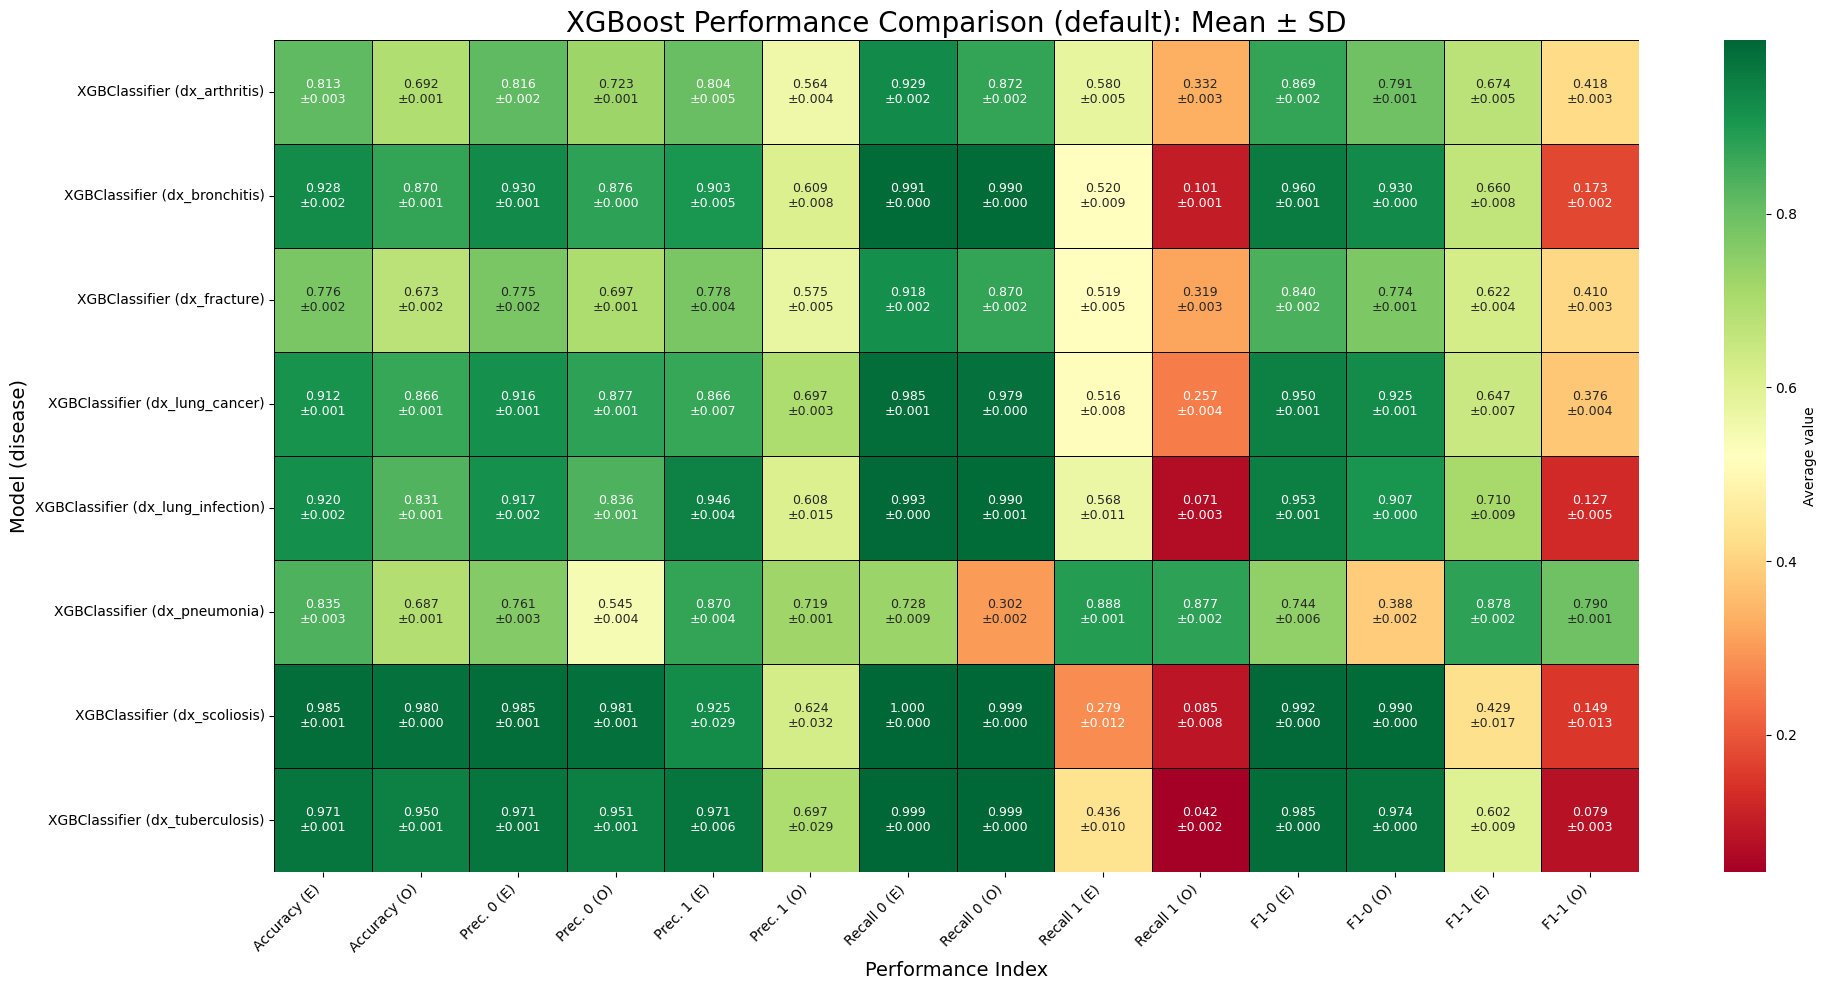

In [9]:
#default
import io

res_default_T = res_default.T
csv_string = res_default_T.to_csv(index=True)
df_data = pd.read_csv(io.StringIO(csv_string))

metrics_to_plot = [
    'acc_e', 'acc_o',
    'p0_e', 'p0_o',
    'p1_e', 'p1_o',
    'r0_e', 'r0_o',
    'r1_e', 'r1_o',
    'f1_0_e', 'f1_0_o',
    'f1_1_e', 'f1_1_o',
]

new_col_names = {
    'acc_e': 'Accuracy (E)', 'acc_o': 'Accuracy (O)',
    'p0_e': 'Prec. 0 (E)', 'p0_o': 'Prec. 0 (O)',
    'p1_e': 'Prec. 1 (E)', 'p1_o': 'Prec. 1 (O)',
    'r0_e': 'Recall 0 (E)', 'r0_o': 'Recall 0 (O)',
    'r1_e': 'Recall 1 (E)', 'r1_o': 'Recall 1 (O)',
    'f1_0_e': 'F1-0 (E)', 'f1_0_o': 'F1-0 (O)',
    'f1_1_e': 'F1-1 (E)', 'f1_1_o': 'F1-1 (O)',
}

grouped = df_data.groupby(['Model', 'Disease'])[metrics_to_plot]
mean_df = grouped.mean()
std_df = grouped.std()

new_index = [f"{m} ({d})" for m, d in mean_df.index]
mean_df.index = new_index
std_df.index = new_index

mean_df = mean_df.rename(columns=new_col_names)
std_df = std_df.rename(columns=new_col_names)

annot_df = mean_df.copy().astype(str)
for col in mean_df.columns:
    annot_df[col] = mean_df[col].map('{:.3f}'.format) + "\n±" + std_df[col].map('{:.3f}'.format)

plt.figure(figsize=(20, 10))

sns.heatmap(
    mean_df,
    annot=annot_df,
    fmt="",
    cmap='RdYlGn',
    linewidths=.5,
    linecolor='black',
    annot_kws={"size": 9},
    cbar_kws={'label': 'Average value'}
)

plt.title('XGBoost Performance Comparison (default): Mean ± SD', fontsize=20)
plt.ylabel('Model (disease)', fontsize=14)
plt.xlabel('Performance Index', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()